# Your first Δχ² map with lenscape — reproducing the research-note figure

This tutorial is for first-time users. It assumes nothing beyond a working Python and takes you from a photometry
file to the published-style Δχ² map of the planetary microlensing event **MOA-2022-BLG-091** (Han et al. 2025), the
map shown in our research note, in three steps of increasing resolution:

1. the 50 × 49 lattice of the published map, computed from scratch;
2. a 2× finer map (99 × 97 points) built from the first;
3. a 4× finer map (197 × 193 points) built from the first two.

Everything runs with lenscape's defaults. The runtimes quoted below were measured on a 16-core AMD Ryzen 9 7950X
(32 threads); on a laptop with 8 threads expect about four times longer.

**What a Δχ² map is.** A binary-lens model has seven parameters: the time of closest approach *t*₀, the impact
parameter *u*₀, the Einstein time *t*ₑ, the lens separation *s* and mass ratio *q*, the trajectory angle α, and
the source size ρ. The map fixes *s* and *q* on a lattice and, at every lattice point, fits the other five
parameters (and the fluxes of each data set). The quantity shown is Δχ² = χ² − χ²ₘᵢₙ: dark red is the best model,
and every coloured valley is a family of models that explains the data almost as well. For planetary events the
map typically shows several such valleys (the *degenerate solutions*); seeing them all is the point of the map.

## 0. Installation

```bash
pip install "lenscape[plot]"
```

(or, from a clone of the repository, `pip install -e ".[plot]"`). The first import compiles the numerical kernels
with numba, which takes about two minutes once; they are cached afterwards.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import figures

print("lenscape", lenscape.__version__)

lenscape 0.1.0


## 1. The photometry

The file `data/moa091_photometry.csv` holds the data behind our figure: the KMTNet and MOA points of Han et al.
(2025) as plotted in their Fig. 1, plus the public KMTNet baseline outside the plotted window (it constrains the
blending), 2 531 points in four data sets. One row per measurement:

| column | meaning |
|---|---|
| `set` | telescope / data set (KMTA22, KMTC22, KMTS22 = KMTNet Australia, Chile, South Africa; MOA22) |
| `t` | time, HJD − 2450000 (days) |
| `mag` | magnitude on an arbitrary zero point |
| `mag_err` | its error |

lenscape works in *flux*. We convert the magnitudes (any zero point will do: the source and blend fluxes are free
parameters of every fit) and build a `lenscape.Data` object from a dictionary `{name: (t, flux, flux_error)}`. Your
own data go in the same way: one `(t, flux, error)` triple per telescope.

In [2]:
rows = np.genfromtxt("data/moa091_photometry.csv", delimiter=",", names=True, dtype=None, encoding="utf-8",
                     skip_header=3)                     # the first three lines are comments
sets = {}
for name in ["KMTA22", "KMTC22", "KMTS22", "MOA22"]:
    r = rows[rows["set"] == name]
    flux = 10 ** (-0.4 * (r["mag"] - 22.0))               # zero point 22: flux 1 at mag 22
    flux_err = flux * 0.4 * np.log(10) * r["mag_err"]
    sets[name] = (r["t"], flux, flux_err)
data = lenscape.Data.from_sets(sets)
data

Data(2531 points, t 9630.85 .. 9874.29, sets {'KMTA22': 436, 'KMTC22': 1128, 'KMTS22': 722, 'MOA22': 245})

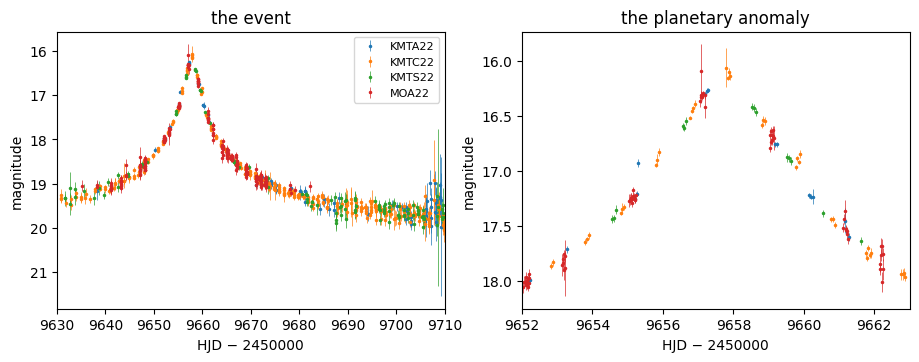

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, window in zip(ax, [(9630, 9710), (9652, 9663)]):
    for k, name in enumerate(data.names):
        sel = (data.idx == k) & (data.t > window[0]) & (data.t < window[1])
        a.errorbar(data.t[sel], 22 - 2.5 * np.log10(data.f[sel]), 2.5 / np.log(10) * data.e[sel] / data.f[sel],
                   fmt=".", ms=3, lw=0.5, label=name)
    a.invert_yaxis(); a.set_xlabel("HJD − 2450000"); a.set_ylabel("magnitude"); a.set_xlim(window)
ax[0].legend(fontsize=8); ax[0].set_title("the event"); ax[1].set_title("the planetary anomaly");

The bump on the falling side of the peak (right panel, around day 9659.5) is the planet's signature: the
source passed a caustic of the lens system. Where exactly it passed is what the map will tell us.

## 2. A starting model

A map needs one reasonable model of the event as its starting point, as a vector of the seven parameters
`(t0, u0, tE, log10 s, log10 q, alpha, log10 rho)` (lenscape uses the decadic logarithms of *s*, *q* and ρ, and α in
radians). For a new event you would obtain it with `lenscape.fit_full` from a rough guess, or from a coarse map
(see notebook `06_maps`). Here we use the best fit of this data set, stored with the notebooks. It does not matter
which of the degenerate solutions you start from: the map covers all of them.

In [4]:
best = np.array([9657.774, -0.026139, 34.593, 0.0021016, -2.37157, 4.40428, -2.98889])
chi2 = lenscape.model.chi2(lenscape.make_backend(lenscape.config.REFINE_BACKEND), best, data)
print(f"chi2 = {chi2:.1f} for {len(data)} points;  s = {10 ** best[3]:.4f}, q = {10 ** best[4]:.2e}, "
      f"alpha = {best[5]:.3f}, tE = {best[2]:.2f} d")

chi2 = 2445.7 for 2531 points;  s = 1.0049, q = 4.25e-03, alpha = 4.404, tE = 34.59 d


## 3. Stage 1: the 50 × 49 lattice from scratch

The lattice of the published map: 50 points in log *s* from −0.0100 to 0.0160 and 49 points in log *q* from
−2.600 to −2.013 (the values are the paper's, measured from its figure). `lenscape.lattice` takes the data, the two
axes and the starting model, and computes the map in stages (printed as it goes):

* a coarse seed grid and *cell fits* with *s* and *q* free inside each cell, so that a narrow valley between
  lattice points cannot be missed;
* the *lattice-point fits* at fixed (*s*, *q*), started from the cell solutions around each point;
* a *neighbour refinement*: every point is refitted from its neighbours' solutions (also at other source sizes)
  until no point improves any more, because a fit on its own often stops in a local minimum;
* a deep search at points that still stand above their neighbours.

It uses all CPU threads by default (`workers=`). **Runtime on the 7950X for this step: 14 minutes.**

In [5]:
dls, dlq = 0.0005302923409363749, 0.012238426224489748              # the lattice steps of the published map
logs1 = -0.010006002352941175 + dls * np.arange(50)
logq1 = -2.59991008653061 + dlq * np.arange(49)

t = time.time()
map1 = lenscape.lattice(data, logs1, logq1, best=best)
print(f"wall time {(time.time() - t) / 60:.1f} min")

lattice 50 x 49 = 2450 points; N = 2531 (1325 evaluated after binning the wings)



Stage 1/5: Coarse seed grid - quick fits on 2 x 2 merged cells, used as starting points


seed grid: neighbour refinement: 1251 points checked, 221 improved
  seed grid: neighbour refinement: 1251 cells checked, 221 improved by > 1.0
seed grid 25 x 25: 846 fits, 91s, min 2445.53

Stage 2/5: Cell fits - best fit inside each cell


neighbour refinement: 2719 points checked, 260 improved
  neighbour refinement: 2719 cells checked, 260 improved by > 1.0
cells: 2450 fits, 344s, best chi2 2445.53

Stage 3/5: Lattice point fits - s and q fixed at each lattice point, started from the cell fits



Stage 4/5: Neighbour refinement - refit points whose neighbours found a better solution


neighbour refinement: 4734 points checked, 1427 improved (767 by less than 1)

Stage 5/5: Recalculate outliers - deep search for points that are worse than their neighbours


recalculate outliers, pass 1: 73 outliers, 12 improved


recalculate outliers, pass 2: 10 outliers, 4 improved


recalculate outliers, pass 3: 6 outliers, 3 improved


recalculate outliers, pass 4: 1 outliers, 1 improved
done in 1747s; lowest chi2 2445.53
wall time 29.1 min


The result is a dictionary: `map1["chi2"]` is the χ² at every lattice point (shape 50 × 49), `map1["pars"]` the
fitted parameters there, `map1["chi2_ref"]` the lowest χ² found. `figures.plot_map` draws Δχ² on a logarithmic
colour scale up to 100.

minimum chi2 = 2445.5 at log s = 0.0017, log q = -2.367


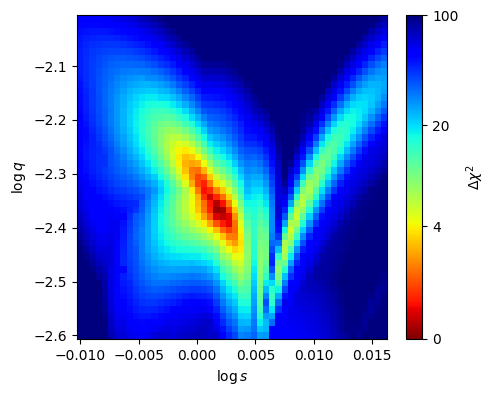

In [6]:
figures.plot_map(map1);
i, j = np.unravel_index(np.nanargmin(map1["chi2"]), map1["chi2"].shape)
print(f"minimum chi2 = {map1['chi2_ref']:.1f} at log s = {logs1[i]:.4f}, log q = {logq1[j]:.3f}")

You should see the V-shaped valley of the published map: the broad minimum at log *s* ≈ 0.002, log *q* ≈ −2.37,
the narrow arm towards larger *s*, and the gap between them at log *s* ≈ 0.006–0.008. The four published solutions
A–D lie along these valleys.

## 4. Stage 2: twice the resolution

`lenscape.maps.densify` builds a finer map from the maps you already have: every new point is fitted from the
nearest known solutions instead of from scratch, then refined as before. The finer axes have twice as many points
with half the step, and `[map1]` is the list of maps to start from. **Runtime on the 7950X for this step:
8 minutes.**


Stage 1/3: Lattice point fits - 9603 points started from the 3 nearest of 2450 known solutions



Stage 2/3: Neighbour refinement - refit points whose neighbours found a better solution


neighbour refinement: 10928 points checked, 696 improved (3108 by less than 1)

Stage 3/3: Recalculate outliers - deep search for points that are worse than their neighbours


recalculate outliers, pass 1: 53 outliers, 8 improved


recalculate outliers, pass 2: 8 outliers, 1 improved
done in 1137s; lowest chi2 2445.50
wall time 18.9 min


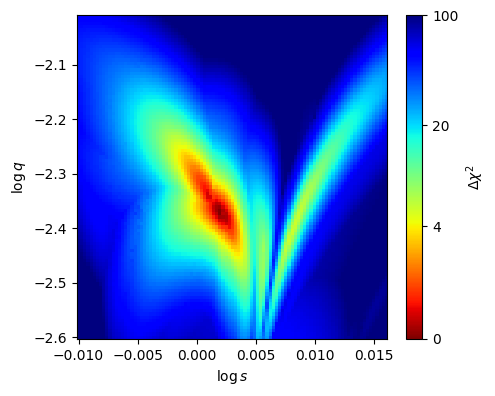

In [7]:
logs2 = logs1[0] + dls / 2 * np.arange(99)
logq2 = logq1[0] + dlq / 2 * np.arange(97)

t = time.time()
map2 = lenscape.maps.densify([map1], data, logs2, logq2, best=best)
print(f"wall time {(time.time() - t) / 60:.1f} min")
figures.plot_map(map2);

## 5. Stage 3: four times the resolution

The same step again, now started from both earlier maps. **Runtime on the 7950X for this step: 23 minutes.**
One more doubling (393 × 385 points, 74 minutes) gives panel (b) of the research note; together 119 minutes.


Stage 1/3: Lattice point fits - 38021 points started from the 3 nearest of 12053 known solutions



Stage 2/3: Neighbour refinement - refit points whose neighbours found a better solution


task (186, 19): python error ZeroDivisionError('complex division by zero')


neighbour refinement: 39515 points checked, 1282 improved (11587 by less than 1)

Stage 3/3: Recalculate outliers - deep search for points that are worse than their neighbours


recalculate outliers, pass 1: 50 outliers, 10 improved


recalculate outliers, pass 2: 5 outliers, 3 improved


recalculate outliers, pass 3: 6 outliers, 0 improved
done in 3251s; lowest chi2 2445.49
wall time 54.2 min


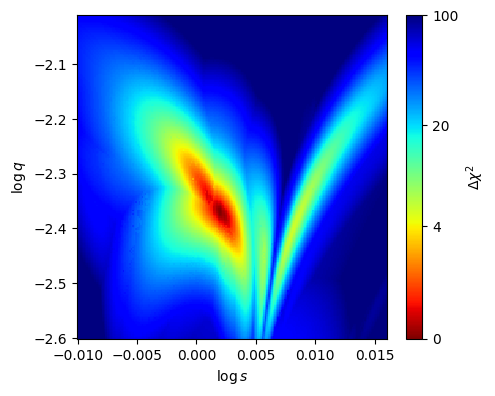

In [8]:
logs4 = logs1[0] + dls / 4 * np.arange(197)
logq4 = logq1[0] + dlq / 4 * np.arange(193)

t = time.time()
map4 = lenscape.maps.densify([map1, map2], data, logs4, logq4, best=best)
print(f"wall time {(time.time() - t) / 60:.1f} min")
figures.plot_map(map4);

## 6. Saving and next steps

The maps are plain arrays; save them with numpy and load them later without recomputing.

In [9]:
for name, m in [("map_1x", map1), ("map_2x", map2), ("map_4x", map4)]:
    np.savez(f"data/tutorial_{name}.npz", logs=m["logs"], logq=m["logq"], chi2=m["chi2"], pars=m["pars"],
             chi2_ref=m["chi2_ref"])
print("saved data/tutorial_map_{1x,2x,4x}.npz")

saved data/tutorial_map_{1x,2x,4x}.npz


Where to go from here:

* `01_quickstart` — the same pipeline on freshly downloaded public photometry, including the fit and the error-bar
  normalisation that produced the starting model used above;
* `06_maps` — what each stage of the map does, and the trajectory-angle (log *s*, α) profile of panel (d);
* `han2025_figures` — all figures of Han et al. (2025) redrawn with lenscape, including how the data in the CSV
  were rebuilt from the paper's vector graphics;
* `05_fitting`, `08_mcmc`, `09_physical_parameters` — from a map to the physical parameters of the planet.